# General relativity 6: Light bending and black hole shadows

*Learning path: general relativity, part 6 of 9.* [Index](README.md) · Previous: [Orbits](05-orbits.ipynb) · Next: [Clocks and GPS](07-clocks-and-gps.ipynb)

Light follows *null* geodesics, with $g_{ab}\dot x^a\dot x^b = 0$. Near a mass they bend. You will learn

* the effective potential for light and the photon sphere at $1.5\,r_s$,
* how a black hole bends a beam of light, and captures part of it,
* the 1.75 arcseconds of the 1919 eclipse, which made Einstein famous,
* how big the shadow of the M87 black hole should look, and what the Event Horizon Telescope saw.

## 1. The photon sphere

For light with impact parameter $b$ (how far off-centre it is aimed), the radial motion obeys

$$\left(\frac{dr}{d\lambda}\right)^2 + V(r) = \frac{1}{b^2}, \qquad V(r) = \frac{1}{r^2}\left(1 - \frac{r_s}{r}\right)$$

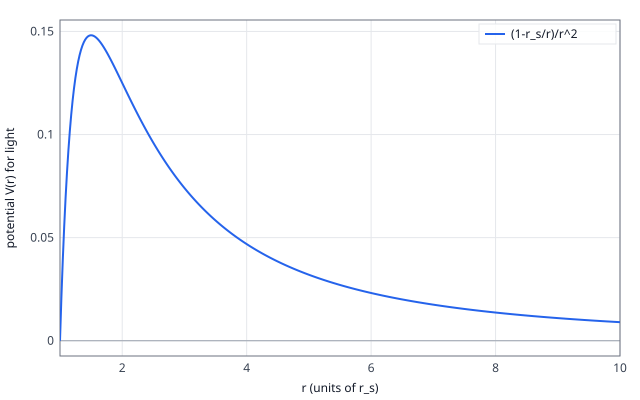

In [1]:
r_s = 1;
labels(plot((1 - r_s/r)/r^2, r, 1, 10), "r (units of r_s)", "potential V(r) for light")

The potential has a single peak, at $r = 1.5\,r_s$, of height $4/(27r_s^2)$. Light can circle the black hole there, on an
unstable orbit: the **photon sphere** [1]. Light coming in with $1/b^2$ above the peak, that is $b < b_c = \tfrac{3\sqrt3}{2}r_s$,
falls in; with $b > b_c$ it swings around and escapes.

In [2]:
bc = eval(3*sqrt(3)/2)

2.598076211353316

## 2. A beam of light past a black hole

Send parallel rays from the left, starting at $x = -15$, at heights $b$ from 2 to 6. For each ray we set the starting
position $(r_0, \phi_0)$ and the velocity: $\dot r = -15/r_0$, $\dot\phi = -b/r_0^2$, and $\dot t$ so that the
velocity is null.

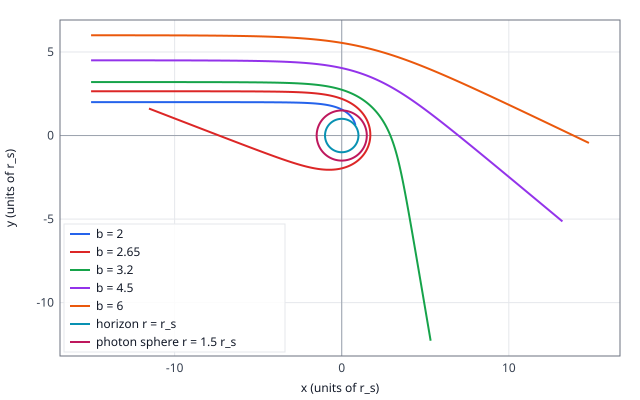

In [3]:
S = metric.generate(schwarzschild);
b = 2;
r0 = sqrt(225+b^2); p0 = pi-atan(b/15); vr = -15/r0; vp = -b/r0^2; f = 1-r_s/r0; ut = sqrt((vr^2/f + r0^2*vp^2)/f);
ray1 = geodesic(S, [0 r0 pi/2 p0], [ut vr 0 vp], 30, [r*cos(phi) r*sin(phi)]);
b = 2.65;
r0 = sqrt(225+b^2); p0 = pi-atan(b/15); vr = -15/r0; vp = -b/r0^2; f = 1-r_s/r0; ut = sqrt((vr^2/f + r0^2*vp^2)/f);
ray2 = geodesic(S, [0 r0 pi/2 p0], [ut vr 0 vp], 30, [r*cos(phi) r*sin(phi)]);
b = 3.2;
r0 = sqrt(225+b^2); p0 = pi-atan(b/15); vr = -15/r0; vp = -b/r0^2; f = 1-r_s/r0; ut = sqrt((vr^2/f + r0^2*vp^2)/f);
ray3 = geodesic(S, [0 r0 pi/2 p0], [ut vr 0 vp], 30, [r*cos(phi) r*sin(phi)]);
b = 4.5;
r0 = sqrt(225+b^2); p0 = pi-atan(b/15); vr = -15/r0; vp = -b/r0^2; f = 1-r_s/r0; ut = sqrt((vr^2/f + r0^2*vp^2)/f);
ray4 = geodesic(S, [0 r0 pi/2 p0], [ut vr 0 vp], 30, [r*cos(phi) r*sin(phi)]);
b = 6;
r0 = sqrt(225+b^2); p0 = pi-atan(b/15); vr = -15/r0; vp = -b/r0^2; f = 1-r_s/r0; ut = sqrt((vr^2/f + r0^2*vp^2)/f);
ray5 = geodesic(S, [0 r0 pi/2 p0], [ut vr 0 vp], 30, [r*cos(phi) r*sin(phi)]);
horizon = parametric(cos(q), sin(q), q, 0, 2*pi);
photonsphere = parametric(1.5*cos(q), 1.5*sin(q), q, 0, 2*pi);
labels(legend(show(ray1, ray2, ray3, ray4, ray5, horizon, photonsphere), "b = 2", "b = 2.65", "b = 3.2", "b = 4.5", "b = 6", "horizon r = r_s", "photon sphere r = 1.5 r_s"), "x (units of r_s)", "y (units of r_s)")

The ray at $b = 2$ is below $b_c$ and falls in. The ray at $b = 2.65$, just above $b_c \approx 2.6$, whips around the
photon sphere and leaves in a completely different direction. Rays further out are bent less and less.

## 3. A flash of light

Light emitted in all directions from $r = 3\,r_s$: rays aimed outwards escape, bent; rays aimed inwards cross the horizon.
Each row of the velocity matrix is one ray, leaving at angle $A$ from the outward direction:
$(\dot t, \dot r, \dot\theta, \dot\phi) = (1/k,\; k\cos A,\; 0,\; \sin A/r_0)$ with $k = \sqrt{1 - r_s/r_0}$.

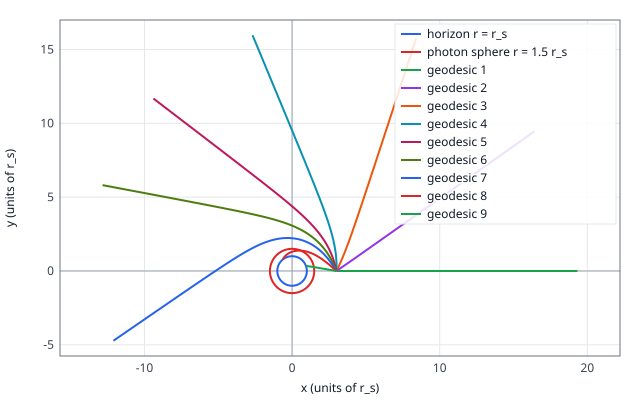

In [4]:
r0 = 3;
k = sqrt(1-r_s/r0);
ut = 1/k;
rays = geodesic(S, [0 r0 pi/2 0], [ut, k, 0, 0; ut, k*cos(0.5), 0, sin(0.5)/r0; ut, k*cos(1), 0, sin(1)/r0; ut, k*cos(1.5), 0, sin(1.5)/r0; ut, k*cos(1.8), 0, sin(1.8)/r0; ut, k*cos(2.0), 0, sin(2.0)/r0; ut, k*cos(2.2), 0, sin(2.2)/r0; ut, k*cos(2.5), 0, sin(2.5)/r0; ut, k*cos(3), 0, sin(3)/r0], 20, [r*cos(phi) r*sin(phi)]);
labels(legend(show(horizon, photonsphere, rays), "horizon r = r_s", "photon sphere r = 1.5 r_s"), "x (units of r_s)", "y (units of r_s)")

## 4. Eddington's eclipse

Far from the mass, a ray with impact parameter $b$ is deflected by $\delta = 2r_s/b = 4GM/(c^2b)$, twice what a
Newtonian argument gives [2]. For starlight grazing the Sun, in arcseconds:

In [5]:
clear
GM = 1.32712440018e20;
c = 299792458;
Rsun = 6.957e8;
eval(4*GM/(c^2*Rsun)*(180/pi)*3600)

1.7511903257975012

1.75 arcseconds. During the total eclipse of 29 May 1919, expeditions led by Arthur Eddington photographed stars near
the darkened Sun and found them shifted by about this amount [3]. "Lights all askew in the heavens", ran the *New York Times* headline
[4], and Einstein became a celebrity overnight. Today the same effect, *gravitational
lensing*, is used to weigh galaxy clusters and map dark matter.

## 5. The shadow of a black hole

Rays with $b < b_c$ fall in, so a black hole in front of a bright background appears as a dark disc of radius $b_c$,
larger than the horizon. For the black hole in the galaxy M87, with mass 6.5 billion Suns at a distance of 16.8
megaparsecs [5], the shadow's angular diameter $2b_c/D$ in microarcseconds is

In [6]:
G = 6.674e-11;
M = 6.5e9*1.989e30;
D = 16.8*3.086e22;
rs = eval(2*G*M/c^2);
eval(2*(3*sqrt(3)/2)*rs/D*(180/pi)*3600*1e6)

39.693988880430894

About 40 microarcseconds: an 8 cm orange at the distance of the Moon looks about this big. In 2019 the Event Horizon Telescope, a
network of radio telescopes the size of the Earth, imaged a ring of diameter 42 ± 3 microarcseconds around a dark
centre [5]. General relativity passed another test, in a regime far stronger than the Sun's.

## Summary

* Light follows null geodesics; its effective potential peaks at the photon sphere, $r = 1.5\,r_s$.
* Rays with impact parameter below $b_c = \tfrac{3\sqrt3}{2}r_s$ are captured; that makes the shadow.
* Grazing the Sun, light bends by $4GM/(c^2R) = 1.75''$.

**Try it:** in section 2, try $b = 2.61$ and $b = 2.6$. Near $b_c$ the ray can circle the black hole several times.

Next: [Clocks and GPS](07-clocks-and-gps.ipynb).

## Sources

Numbers in square brackets in the text refer to this list.

1. C. W. Misner, K. S. Thorne and J. A. Wheeler, *Gravitation*, W. H. Freeman (1973). Section 25.6 (photon orbits and capture cross-section).
2. A. Einstein, "Erklärung der Perihelbewegung des Merkur aus der allgemeinen Relativitätstheorie", *Sitzungsberichte der Preußischen Akademie der Wissenschaften*, 831–839 (1915): light deflection 1.7″ at the Sun's limb.
3. F. W. Dyson, A. S. Eddington and C. Davidson, "A determination of the deflection of light by the Sun's gravitational field, from observations made at the total eclipse of May 29, 1919", *Philosophical Transactions of the Royal Society A* **220**, 291–333 (1920). [doi:10.1098/rsta.1920.0009](https://doi.org/10.1098/rsta.1920.0009)
4. "Lights all askew in the heavens; men of science more or less agog over results of eclipse observations", *The New York Times*, 10 November 1919, p. 17.
5. Event Horizon Telescope Collaboration, "First M87 Event Horizon Telescope results. I. The shadow of the supermassive black hole", *Astrophysical Journal Letters* **875**, L1 (2019), [doi:10.3847/2041-8213/ab0ec7](https://doi.org/10.3847/2041-8213/ab0ec7); "... VI. The shadow and mass of the central black hole", **875**, L6 (2019), [doi:10.3847/2041-8213/ab1141](https://doi.org/10.3847/2041-8213/ab1141).